# Где поставить 40 кофейных автоматов

## 1. Цель
Фиксирую решение до расчётов: риск убытка не больше 2.5%, среди прошедших городов максимум средней годовой маржи. Затраты 140 тыс. ₽/автомат в год, обследование 300 разных адресов, установка 40. Модель выбирает адреса по прогнозу, оценка считается по фактам.

## 2. Данные
Ученический sites.csv, 4500 адресов, по 1500 на город. Данные синтетического задания; путь COURSE_DATA или ../technical/data-baseline.

In [1]:
import os,json,sys,platform
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_squared_error
from IPython.display import display,Markdown
RANDOM_STATE=42
DATA=Path(os.environ.get('COURSE_DATA','../technical/data-baseline'))
OUT=Path('sites-artifacts'); OUT.mkdir(exist_ok=True)
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'runtime':'native Python; browser exercise runtime differs'}
print(versions)
s=pd.read_csv(DATA/'sites.csv')
assert s.site_id.is_unique and s.shape[0]==4500
assert s.groupby('city').size().eq(1500).all()
assert s.traffic.gt(0).all()
overview=s.groupby('city').agg(sites=('site_id','size'),mean_profit=('profit_k','mean'),pays_off=('profit_k',lambda x:(x>140).mean()))
display(overview.round(3))


{'python': '3.12.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'sklearn': '1.8.0', 'runtime': 'native Python; browser exercise runtime differs'}


,sites,mean_profit,pays_off
city,,,
Екатеринбург,1500,70.899,0.291
Казань,1500,66.941,0.206
Пермь,1500,65.151,0.159


**Вывод по данным.** Проверены уникальность адресов, размер городов и положительность traffic перед log. pays_off — доля отдельных мест выше 140 тыс., она ещё не решает задачу портфеля 40.

## 3. Предобработка

In [2]:
def prep(part):
    X=pd.get_dummies(part[['place','traffic','offices','competitors','rent_k','hours24']],dtype=int)
    X['traffic']=np.log(X.traffic)
    return X
fits={}
for city,part in s.groupby('city'):
    X=prep(part)
    xt,xv,yt,yv=train_test_split(X,part.profit_k,test_size=.25,random_state=42)
    m=LinearRegression().fit(xt,yt)
    fits[city]=(pd.Series(m.predict(xv),index=yv.index),yv)
COST,K,SURVEY=140,40,300
def boot_city(pred,fact):
    rng=np.random.default_rng(0)
    p,f=np.asarray(pred),np.asarray(fact)
    out=[]
    for _ in range(1000):
        i=rng.choice(len(f),SURVEY,replace=False)
        out.append(f[i[np.argsort(-p[i])[:K]]].sum()-K*COST)
    return np.array(out)


**Вывод по подготовке.** Из входов исключены ID, город и target. Категория place раскрыта в флаги; логарифм трафика применяется построчно. Все возможные категории заданы обследованным реестром; это не оценка статистики по target.

## 4. Анализ и модели

In [3]:
quality=[]
top=[]
for city,(p,f) in fits.items():
    ids=p.nlargest(K).index
    quality.append({'city':city,'r2':r2_score(f,p),'rmse':np.sqrt(mean_squared_error(f,p))})
    top.append({'city':city,'actual':f.loc[ids].sum()-K*COST,'promised':p.loc[ids].sum()-K*COST,'random':K*f.mean()-K*COST})
quality=pd.DataFrame(quality).set_index('city')
top=pd.DataFrame(top).set_index('city')
display(quality.round(3),top.round(1))
display(Markdown('**Вывод по моделям.** Предсказываем прибыль до обслуживания автомата, а решение проверяем по фактической марже выбранных мест. Исходные города сопоставляются по общей экономике, хотя линейные зависимости учатся отдельно. Случайный выбор имеет тот же размер 40.'))


,r2,rmse
city,,
Екатеринбург,0.230,112.794
Казань,0.491,61.849
Пермь,0.730,37.829


,actual,promised,random
city,,,
Екатеринбург,1475,1176.1,-2779.1
Казань,619,997.0,-3083.4
Пермь,1479,1193.2,-2882.6


**Вывод по моделям.** Предсказываем прибыль до обслуживания автомата, а решение проверяем по фактической марже выбранных мест. Исходные города сопоставляются по общей экономике, хотя линейные зависимости учатся отдельно. Случайный выбор имеет тот же размер 40.

### Риск конечного реестра
В каждом повторе 300 адресов без возвращения, лучшие 40 по прогнозу, сумма фактов минус 5600 тыс. ₽. Функция названа boot_city по заданию, однако это сценарное обследование конечного реестра без возвращения.

,mean,low,high,p_loss
Екатеринбург,1479,803,2207,0.000
Казань,523,132,903,0.008
Пермь,1149,783,1431,0.000


Города прошли: ['Екатеринбург', 'Казань', 'Пермь'] Решение: Екатеринбург


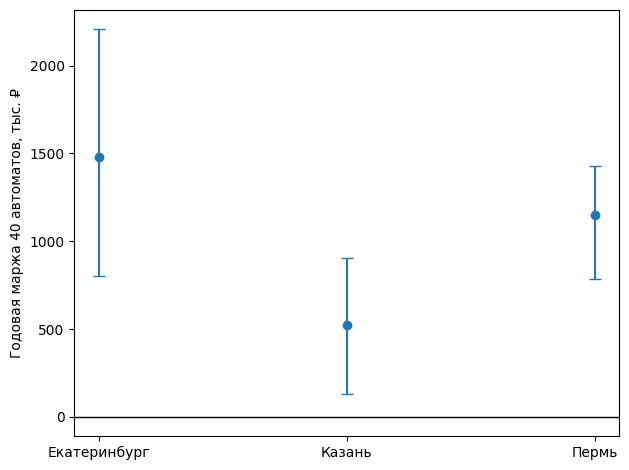

In [4]:
rows={}
for city,(pred,fact) in fits.items():
    profits=boot_city(pred,fact)
    low,high=np.percentile(profits,[2.5,97.5])
    rows[city]={'mean':round(profits.mean()),'low':round(low),'high':round(high),'p_loss':round((profits<0).mean(),3)}
risk=pd.DataFrame.from_dict(rows,orient='index')
passed=risk.index[risk.p_loss<=.025].tolist()
choice=risk.loc[passed,'mean'].idxmax() if passed else None
display(risk)
print('Города прошли:',passed,'Решение:',choice)
risk.to_csv(OUT/'risk.csv')
quality.to_csv(OUT/'quality.csv')
top.to_csv(OUT/'top40-comparison.csv')
fig,ax=plt.subplots()
ax.errorbar(np.arange(len(risk)),risk['mean'],yerr=[risk['mean']-risk.low,risk.high-risk['mean']],fmt='o',capsize=4)
ax.set_xticks(np.arange(len(risk)),risk.index)
ax.axhline(0,color='black',linewidth=1)
ax.set_ylabel('Годовая маржа 40 автоматов, тыс. ₽')
fig.tight_layout();fig.savefig(OUT/'risk.png');plt.show()


In [5]:
if choice is not None:
    p,f=fits[choice]
    # One concrete survey drawn without replacement; the final 40 IDs are unique.
    rng=np.random.default_rng(2026)
    survey=rng.choice(len(f),300,replace=False)
    ranked=survey[np.argsort(-p.values[survey])[:40]]
    ids=p.index[ranked]
    chosen=s.loc[ids].copy()
    chosen['predicted_profit_k']=p.loc[ids]
    chosen['net_actual_k']=chosen.profit_k-140
    assert len(chosen)==40 and chosen.site_id.is_unique
    chosen.to_csv(OUT/'chosen-sites.csv',index=False)
    all_test=s.loc[f.index]
    profile=pd.DataFrame({'selected':[len(chosen),chosen.traffic.median(),chosen.competitors.median(),chosen.rent_k.median(),(chosen.profit_k>140).mean()],
                          'all_test':[len(all_test),all_test.traffic.median(),all_test.competitors.median(),all_test.rent_k.median(),(all_test.profit_k>140).mean()]},index=['n','median_traffic','median_competitors','median_rent_k','share_profitable'])
    display(profile,chosen.place.value_counts(normalize=True).round(3))
    profile.to_csv(OUT/'profile.csv')
    display(Markdown(f'**Вывод по выбранным адресам.** Для города {choice} сохранён конкретный список 40 разных адресов из обследования 300; его историческая маржа {chosen.net_actual_k.sum():,.0f} тыс. ₽. Это один сценарий, он не заменяет распределение риска.'))


,selected,all_test
n,40.00,375.00
median_traffic,1210.00,737.00
median_competitors,0.00,1.00
median_rent_k,50.00,60.00
share_profitable,0.55,0.28


place
бизнес-центр    0.800
вуз             0.100
больница        0.075
завод           0.025
Name: proportion, dtype: float64

**Вывод по выбранным адресам.** Для города Екатеринбург сохранён конкретный список 40 разных адресов из обследования 300; его историческая маржа 1,170 тыс. ₽. Это один сценарий, он не заменяет распределение риска.

### Заранее запланированная чувствительность к модели
Лес на тех же разбиениях служит проверкой устойчивости. Решение по линейной модели не подгоняю после просмотра леса.

## 5. Выводы и рекомендации

In [6]:
rows=[]
for city in ['Пермь','Екатеринбург']:
    part=s[s.city==city]
    xt,xv,yt,yv=train_test_split(prep(part),part.profit_k,test_size=.25,random_state=42)
    forest=RandomForestRegressor(n_estimators=100,min_samples_leaf=5,random_state=0,n_jobs=1).fit(xt,yt)
    p=pd.Series(forest.predict(xv),index=yv.index)
    pr=boot_city(p,yv)
    rows.append({'city':city,'r2':r2_score(yv,p),'mean':pr.mean(),'p_loss':(pr<0).mean()})
rf_risk=pd.DataFrame(rows).set_index('city')
display(rf_risk.round(3))
rf_risk.to_csv(OUT/'forest-sensitivity.csv')
# This was a planned sensitivity analysis, not a new independent model-selection test.
summary={'choice':choice,'passed':passed,'cost_per_machine_k':140,'machines':40,'survey':300,'risk_threshold':.025,'risk':risk.to_dict(orient='index'),'versions':versions}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
(OUT/'versions.json').write_text(json.dumps(versions,ensure_ascii=False,indent=2))
if choice is not None:
    rr=risk.loc[choice]
    display(Markdown(f'**Рекомендация.** Выбираю {choice}: средняя годовая маржа {rr["mean"]:,.0f} тыс. ₽, 95% сценариев от {rr.low:,.0f} до {rr.high:,.0f}, оценка доли убытков {rr.p_loss:.1%}. Стоимость 40 автоматов {40*140:,.0f} тыс. ₽/год. Правило риска <=2.5% выполнено.'))
else:
    display(Markdown('**Рекомендация.** Ни один город не прошёл риск <=2.5%; запуск откладываю.'))
display(Markdown('**Ограничения и следующий шаг.** Сценарии относятся к конечному реестру из 375 известных отложенных адресов на город: это случайность состава обследования, не распределение будущей выручки, ошибок обучения или новых адресов. Тестовые значения использованы для исторической оценки и выбора города, поэтому отбор города также добавляет неопределённость. Прибыль места названа оценкой по похожим точкам; фактическая эксплуатация может отличаться. До договора проверить стоимость аренды, независимость и доступность адресов, в пилоте измерить реальные годовые расходы и сезонность.'))


,r2,mean,p_loss
city,,,
Пермь,0.647,870.303,0.000
Екатеринбург,0.173,787.435,0.014


**Рекомендация.** Выбираю Екатеринбург: средняя годовая маржа 1,479 тыс. ₽, 95% сценариев от 803 до 2,207, оценка доли убытков 0.0%. Стоимость 40 автоматов 5,600 тыс. ₽/год. Правило риска <=2.5% выполнено.

**Ограничения и следующий шаг.** Сценарии относятся к конечному реестру из 375 известных отложенных адресов на город: это случайность состава обследования, не распределение будущей выручки, ошибок обучения или новых адресов. Тестовые значения использованы для исторической оценки и выбора города, поэтому отбор города также добавляет неопределённость. Прибыль места названа оценкой по похожим точкам; фактическая эксплуатация может отличаться. До договора проверить стоимость аренды, независимость и доступность адресов, в пилоте измерить реальные годовые расходы и сезонность.